**Notebook Criado por:** MSc. Eng. Paulo Silva  
**Notebook Criado em:** 16 / 10 / 2026  
**Última Atualização:** 16 / 10 / 2026  

**Obs:** Este notebook foi desenvolvido sob auxílio de ferramentas de IA.

# **Métodos numéricos complementares para a solução de Blasius**

Este notebook apresenta, de forma independente e introdutória, três ferramentas utilizadas na solução de Blasius:

1. integração de equações diferenciais ordinárias por Runge–Kutta;
2. método de shooting e busca da condição inicial desconhecida;
3. interpolação, com destaque para a spline cúbica.

Os exemplos a seguir são matemáticos e foram escolhidos para separar as ideias numéricas da aplicação física. No notebook principal de Blasius, essas mesmas ferramentas aparecem combinadas:

| Ferramenta | Uso no problema de Blasius |
|---|---|
| `solve_ivp` com `RK45` | Integra o sistema associado à equação de Blasius |
| `root_scalar` com `brentq` | Encontra o valor desconhecido de $f''(0)$ |
| `CubicSpline` | Interpola $f(\eta)$ para resolver a camada térmica |

O objetivo aqui não é substituir as aulas de métodos numéricos, mas tornar visível o funcionamento das estratégias utilizadas no código.

## **1. Integração de uma EDO: do problema contínuo ao passo numérico**

Considere o problema de valor inicial

$$
\frac{dy}{dx}=-2y,
\qquad y(0)=1.
$$

A solução exata é

$$
y(x)=e^{-2x}.
$$

Um integrador numérico parte do valor conhecido em $x_i$ e estima o valor seguinte em $x_{i+1}=x_i+h$. O tamanho $h$ é o passo da integração.

Neste exemplo implementaremos Euler e Runge–Kutta de quarta ordem. Em seguida, compararemos ambos com o `RK45` do `solve_ivp`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline
from scipy.optimize import root_scalar

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def rhs(x, y):
    """EDO do exemplo: y' = -2y."""
    return -2.0 * y


def solucao_exata(x):
    return np.exp(-2.0 * x)


def euler(ode, x, y0):
    """Método de Euler explícito para uma EDO escalar."""
    x = np.asarray(x)
    y = np.zeros_like(x, dtype=float)
    y[0] = y0

    for i in range(len(x) - 1):
        h = x[i + 1] - x[i]
        y[i + 1] = y[i] + h * ode(x[i], y[i])

    return y


def rk4(ode, x, y0):
    """Runge-Kutta clássico de quarta ordem para uma EDO escalar."""
    x = np.asarray(x)
    y = np.zeros_like(x, dtype=float)
    y[0] = y0

    for i in range(len(x) - 1):
        h = x[i + 1] - x[i]
        xi = x[i]
        yi = y[i]

        k1 = ode(xi, yi)
        k2 = ode(xi + h / 2.0, yi + h * k1 / 2.0)
        k3 = ode(xi + h / 2.0, yi + h * k2 / 2.0)
        k4 = ode(xi + h, yi + h * k3)

        y[i + 1] = yi + h * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0

    return y

### **O que acontece dentro do RK4?**

Em vez de usar apenas a inclinação no início do intervalo, o RK4 calcula quatro estimativas:

$$
k_1=f(x_i,y_i),
$$

$$
k_2=f\left(x_i+\frac{h}{2},y_i+\frac{h}{2}k_1\right),
$$

$$
k_3=f\left(x_i+\frac{h}{2},y_i+\frac{h}{2}k_2\right),
$$

$$
k_4=f(x_i+h,y_i+hk_3).
$$

Essas estimativas são combinadas pela média ponderada

$$
y_{i+1}=y_i+\frac{h}{6}(k_1+2k_2+2k_3+k_4).
$$

O `RK45` utilizado no notebook de Blasius é uma variante adaptativa. Ele usa um par de fórmulas de ordens 4 e 5 para estimar o erro e modificar automaticamente o tamanho do passo.

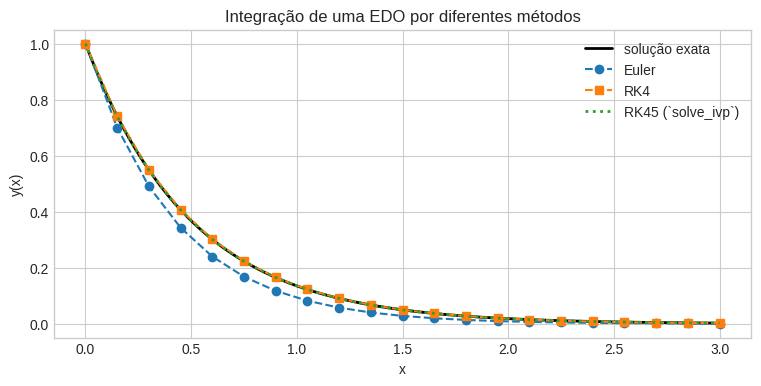

In [3]:
x_inicio = 0.0
x_final = 3.0
y_inicial = 1.0
n_passos = 20

x_malha = np.linspace(x_inicio, x_final, n_passos + 1)
y_euler = euler(rhs, x_malha, y_inicial)
y_rk4 = rk4(rhs, x_malha, y_inicial)

x_rk45 = np.linspace(x_inicio, x_final, 300)
sol_rk45 = solve_ivp(
    rhs,
    (x_inicio, x_final),
    [y_inicial],
    t_eval=x_rk45,
    method="RK45",
    rtol=1e-9,
    atol=1e-11,
)

plt.figure(figsize=(9, 4))
plt.plot(x_rk45, solucao_exata(x_rk45), "k-", linewidth=2, label="solução exata")
plt.plot(x_malha, y_euler, "o--", label="Euler")
plt.plot(x_malha, y_rk4, "s--", label="RK4")
plt.plot(x_rk45, sol_rk45.y[0], ":", linewidth=2, label="RK45 (`solve_ivp`)")
plt.xlabel("x")
plt.ylabel("y(x)")
plt.title("Integração de uma EDO por diferentes métodos")
plt.legend()
plt.show()

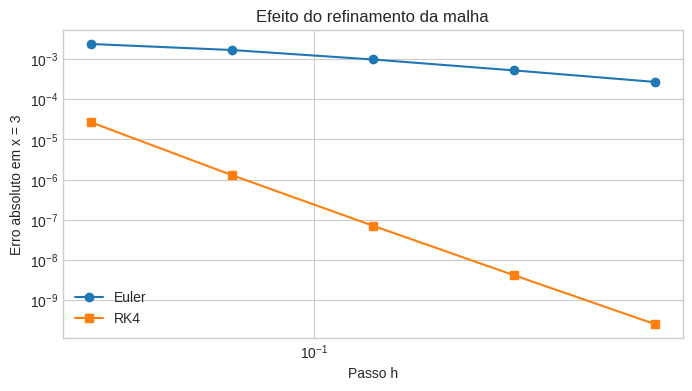

     h          erro Euler          erro RK4
 0.30000     2.373895e-03     2.670250e-05
 0.15000     1.680830e-03     1.290478e-06
 0.07500     9.764509e-04     7.111434e-08
 0.03750     5.228883e-04     4.174612e-09
 0.01875     2.701469e-04     2.528750e-10


In [4]:
passos = np.array([10, 20, 40, 80, 160])
erros_euler = []
erros_rk4 = []

for n in passos:
    x_teste = np.linspace(x_inicio, x_final, n + 1)
    y_eu = euler(rhs, x_teste, y_inicial)
    y_rk = rk4(rhs, x_teste, y_inicial)

    erros_euler.append(abs(y_eu[-1] - solucao_exata(x_final)))
    erros_rk4.append(abs(y_rk[-1] - solucao_exata(x_final)))

hs = (x_final - x_inicio) / passos

plt.figure(figsize=(8, 4))
plt.loglog(hs, erros_euler, "o-", label="Euler")
plt.loglog(hs, erros_rk4, "s-", label="RK4")
plt.xlabel("Passo h")
plt.ylabel("Erro absoluto em x = 3")
plt.title("Efeito do refinamento da malha")
plt.gca().invert_xaxis()
plt.legend()
plt.show()

print("     h          erro Euler          erro RK4")
for h, erro_eu, erro_rk in zip(hs, erros_euler, erros_rk4):
    print(f"{h:8.5f}   {erro_eu:14.6e}   {erro_rk:14.6e}")

## **2. Método de shooting**

Considere agora um problema de valor de contorno:

$$
y''+y=0,
\qquad 0\leq x\leq\frac{\pi}{2},
$$

com

$$
y(0)=0,
\qquad y\left(\frac{\pi}{2}\right)=1.
$$

A solução analítica é $y(x)=\sin(x)$.

O problema não informa diretamente a inclinação inicial $y'(0)$. Por isso, chamaremos essa inclinação desconhecida de $s$:

$$
y(0)=0,
\qquad y'(0)=s.
$$

Para cada valor de $s$, resolvemos um problema de valor inicial. Depois avaliamos o residual

$$
R(s)=y\left(\frac{\pi}{2};s\right)-1.
$$

O shooting consiste em encontrar o valor de $s$ que satisfaz $R(s)=0$.

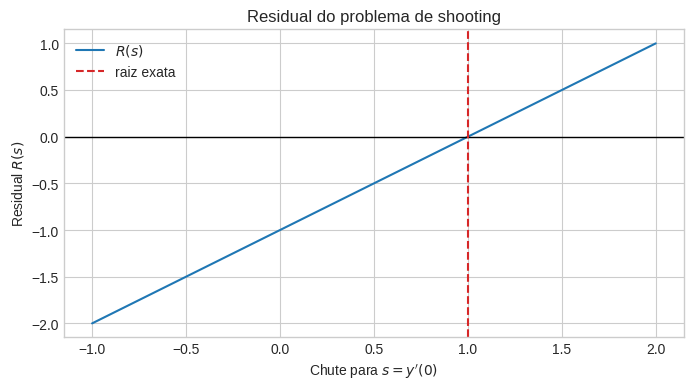

In [5]:
def bvp_ode(x, state):
    """Sistema de primeira ordem para y'' + y = 0."""
    y, dy = state
    return [dy, -y]


x_contorno = np.pi / 2.0


def shooting_residual(slope):
    """Residual no extremo direito para um chute de y'(0)."""
    sol = solve_ivp(
        bvp_ode,
        (0.0, x_contorno),
        [0.0, slope],
        method="RK45",
        rtol=1e-10,
        atol=1e-12,
    )
    return sol.y[0, -1] - 1.0


chutes = np.linspace(-1.0, 2.0, 200)
residuais = np.array([shooting_residual(chute) for chute in chutes])

plt.figure(figsize=(8, 4))
plt.plot(chutes, residuais, label=r"$R(s)$")
plt.axhline(0.0, color="black", linewidth=1)
plt.axvline(1.0, color="tab:red", linestyle="--", label="raiz exata")
plt.xlabel(r"Chute para $s=y'(0)$")
plt.ylabel(r"Residual $R(s)$")
plt.title("Residual do problema de shooting")
plt.legend()
plt.show()

### **Newton, secante e Brent**

Os três métodos procuram uma raiz do residual, mas usam informações diferentes:

| Método | Informação necessária | Característica |
|---|---|---|
| Newton | Um chute e uma derivada do residual | Rápido quando o chute é bom |
| Secante | Dois chutes iniciais | Não exige a derivada analítica |
| `brentq` | Um intervalo com mudança de sinal | Robusto, desde que exista uma raiz no intervalo |

No exemplo, a derivada do residual será estimada por diferenças finitas. Em um problema mais complexo, como Blasius, isso evita a necessidade de deduzir manualmente uma equação de sensibilidade.

In [6]:
def newton_manual(function, x0, tolerance=1e-10, max_iterations=20):
    """Newton com derivada aproximada por diferença central."""
    x = float(x0)
    history = []
    step_for_derivative = 1e-5

    for iteration in range(max_iterations):
        residual = function(x)
        history.append((iteration, x, residual))

        if abs(residual) < tolerance:
            break

        derivative = (
            function(x + step_for_derivative)
            - function(x - step_for_derivative)
        ) / (2.0 * step_for_derivative)

        x = x - residual / derivative

    return x, history


def secant_manual(function, x0, x1, tolerance=1e-10, max_iterations=30):
    """Método da secante."""
    x_previous = float(x0)
    x_current = float(x1)
    history = []

    for iteration in range(max_iterations):
        f_previous = function(x_previous)
        f_current = function(x_current)
        history.append((iteration, x_current, f_current))

        if abs(f_current) < tolerance:
            break

        denominator = f_current - f_previous
        x_next = x_current - f_current * (x_current - x_previous) / denominator
        x_previous, x_current = x_current, x_next

    return x_current, history


root_newton, history_newton = newton_manual(shooting_residual, x0=0.5)
root_secant, history_secant = secant_manual(
    shooting_residual,
    x0=0.2,
    x1=0.8,
)
root_brent = root_scalar(
    shooting_residual,
    bracket=[0.0, 2.0],
    method="brentq",
    xtol=1e-10,
).root

print(f"Newton : s = {root_newton:.10f} | R(s) = {shooting_residual(root_newton):.3e}")
print(f"Secante: s = {root_secant:.10f} | R(s) = {shooting_residual(root_secant):.3e}")
print(f"Brentq : s = {root_brent:.10f} | R(s) = {shooting_residual(root_brent):.3e}")

Newton : s = 1.0000000000 | R(s) = -1.427e-12
Secante: s = 1.0000000000 | R(s) = 6.661e-15
Brentq : s = 1.0000000000 | R(s) = -2.285e-13


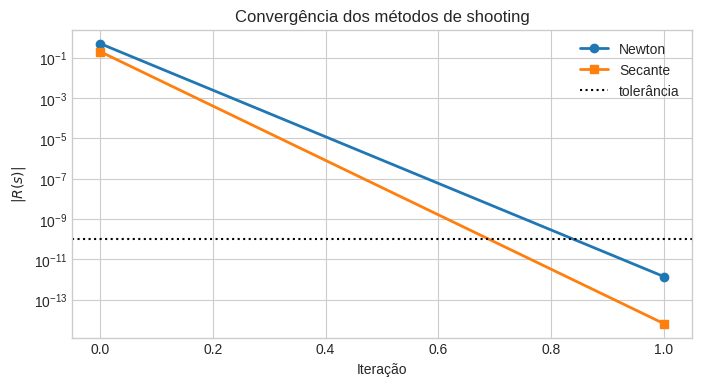

Número de iterações:
Newton : 2
Secante: 2
Brentq : 3


In [7]:
def plot_history(history, label, marker):
    iterations = [item[0] for item in history]
    residuals = [abs(item[2]) for item in history]
    plt.semilogy(
        iterations,
        residuals,
        marker=marker,
        linestyle="-",
        linewidth=2,
        label=label,
    )


plt.figure(figsize=(8, 4))
plot_history(history_newton, "Newton", "o")
plot_history(history_secant, "Secante", "s")

result_brent = root_scalar(
    shooting_residual,
    bracket=[0.0, 2.0],
    method="brentq",
)

plt.axhline(1e-10, color="black", linestyle=":", label="tolerância")
plt.xlabel("Iteração")
plt.ylabel(r"$|R(s)|$")
plt.title("Convergência dos métodos de shooting")
plt.legend()
plt.show()

print("Número de iterações:")
print(f"Newton : {len(history_newton)}")
print(f"Secante: {len(history_secant)}")
print(f"Brentq : {result_brent.iterations}")

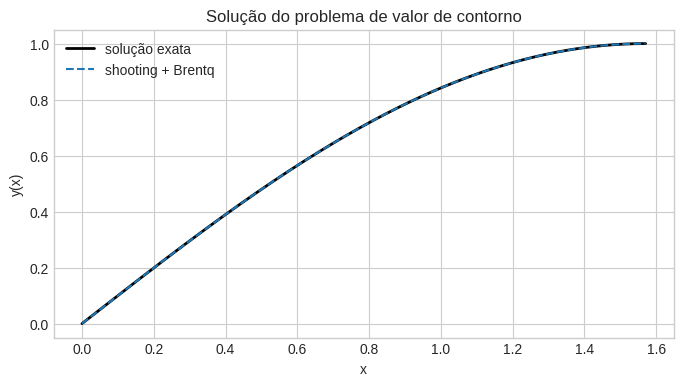

In [8]:
x_solucao = np.linspace(0.0, x_contorno, 300)
sol_shooting = solve_ivp(
    bvp_ode,
    (0.0, x_contorno),
    [0.0, root_brent],
    t_eval=x_solucao,
    rtol=1e-10,
    atol=1e-12,
)

plt.figure(figsize=(8, 4))
plt.plot(x_solucao, np.sin(x_solucao), "k-", linewidth=2, label="solução exata")
plt.plot(x_solucao, sol_shooting.y[0], "--", label="shooting + Brentq")
plt.xlabel("x")
plt.ylabel("y(x)")
plt.title("Solução do problema de valor de contorno")
plt.legend()
plt.show()

### **O que muda no problema de Blasius?**

Em Blasius, o procedimento é o mesmo, mas a equação é não linear e de terceira ordem:

1. transforma-se a equação em um sistema de primeira ordem;
2. escolhe-se um valor para $f''(0)$;
3. integra-se até um valor elevado de $\eta$;
4. calcula-se o residual $f'(\eta_{\max})-1$;
5. utiliza-se um método de busca de raízes para ajustar $f''(0)$.

Assim, o método de shooting não é uma técnica exclusiva de Blasius. Ele é uma estratégia geral para converter um problema de contorno em uma sequência de problemas de valor inicial.

## **3. Interpolação e spline cúbica**

Suponha que conhecemos uma função apenas em alguns pontos. A interpolação constrói uma função aproximada entre esses pontos.

Neste exemplo, os dados vêm de uma função conhecida apenas para que possamos comparar o resultado:

$$
g(x)=e^{-x}\sin(3x).
$$

Vamos comparar a interpolação linear com a spline cúbica.

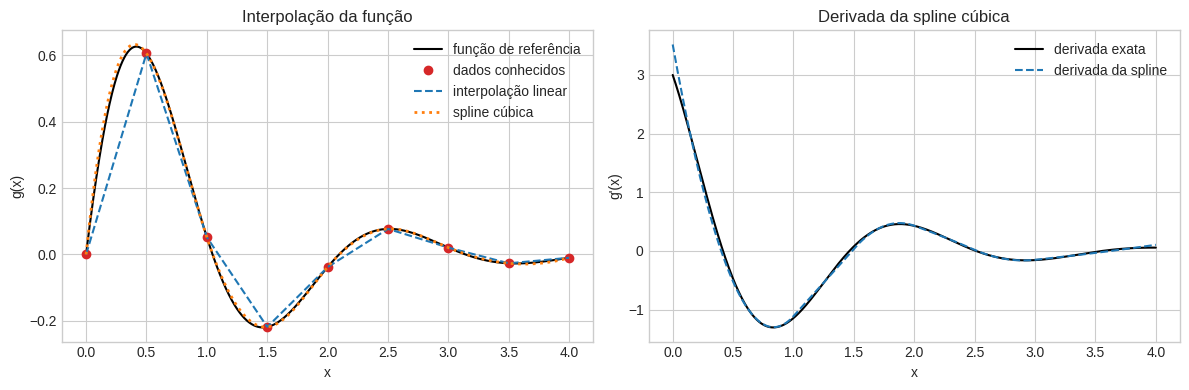

In [9]:
def funcao_referencia(x):
    return np.exp(-x) * np.sin(3.0 * x)


def derivada_referencia(x):
    return np.exp(-x) * (3.0 * np.cos(3.0 * x) - np.sin(3.0 * x))


x_dados = np.linspace(0.0, 4.0, 9)
y_dados = funcao_referencia(x_dados)
x_denso = np.linspace(0.0, 4.0, 800)

y_linear = np.interp(x_denso, x_dados, y_dados)
spline = CubicSpline(x_dados, y_dados)
y_cubica = spline(x_denso)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(x_denso, funcao_referencia(x_denso), "k-", label="função de referência")
axes[0].plot(x_dados, y_dados, "o", color="tab:red", label="dados conhecidos")
axes[0].plot(x_denso, y_linear, "--", label="interpolação linear")
axes[0].plot(x_denso, y_cubica, ":", linewidth=2, label="spline cúbica")
axes[0].set_title("Interpolação da função")
axes[0].set_xlabel("x")
axes[0].set_ylabel("g(x)")
axes[0].legend()

axes[1].plot(x_denso, derivada_referencia(x_denso), "k-", label="derivada exata")
axes[1].plot(x_denso, spline(x_denso, 1), "--", label="derivada da spline")
axes[1].set_title("Derivada da spline cúbica")
axes[1].set_xlabel("x")
axes[1].set_ylabel("g'(x)")
axes[1].legend()

plt.tight_layout()
plt.show()

### **Por que a spline cúbica é útil?**

A interpolação linear conecta os dados por segmentos de reta. A spline cúbica utiliza polinômios cúbicos em cada intervalo e impõe continuidade da função e de suas derivadas nos pontos internos.

No notebook de Blasius, a spline é usada porque o campo $f(\eta)$ é conhecido numericamente em uma malha, mas o integrador térmico pode solicitar seu valor em posições intermediárias. A spline fornece uma função contínua aproximada para essas avaliações.

É importante lembrar que interpolação e extrapolação são situações diferentes. A spline é confiável dentro do intervalo em que os dados foram fornecidos; fora desse intervalo, seu comportamento pode não representar a função original.

In [10]:
erro_linear = np.max(np.abs(y_linear - funcao_referencia(x_denso)))
erro_cubico = np.max(np.abs(y_cubica - funcao_referencia(x_denso)))

print(f"Erro máximo da interpolação linear: {erro_linear:.6e}")
print(f"Erro máximo da spline cúbica      : {erro_cubico:.6e}")

Erro máximo da interpolação linear: 2.284179e-01
Erro máximo da spline cúbica      : 3.150709e-02


## **Resumo da conexão com a aula de Blasius**

No notebook principal, os métodos aparecem da seguinte maneira:

```python
solve_ivp(..., method="RK45")
```

integra o sistema de equações de Blasius;

```python
root_scalar(..., method="brentq")
```

ajusta o valor desconhecido de $f''(0)$;

```python
CubicSpline(eta, f)
```

constrói uma função contínua aproximada para $f(\eta)$.

Essas três ferramentas não substituem a formulação física. Elas são estratégias numéricas para resolver cada parte do problema depois que as equações e condições de contorno foram definidas.

## **Referências para aprofundamento**

- CHAPRA, S. C.; CANALE, R. P. *Métodos Numéricos para Engenharia*.
- BURDEN, R. L.; FAIRES, J. D. *Numerical Analysis*.
- HAIRER, E.; NØRSETT, S. P.; WANNER, G. *Solving Ordinary Differential Equations I: Nonstiff Problems*.
- Documentação do SciPy: `solve_ivp`, `root_scalar` e `CubicSpline`.

O notebook principal de Blasius reúne essas ferramentas em um problema de camada-limite hidrodinâmica e térmica.